# Linear regression and optimization

**Advertising data · NumPy and scikit-learn**

This notebook compares how least squares, mini-batch gradient descent, and
stochastic gradient descent fit the same linear model, including differences
in convergence and runtime. A scikit-learn implementation checks the
numerical solution.

The core algorithms live in `algorithms.py`; this notebook imports them and
the shared experiment in `experiments.py`. All outputs below come from running
the code cells in order. No saved model is required.

**Before running:** follow the repository README to install the environment,
then run `python -m linear_regression.data --download` from the repository root.
Select the `.venv` kernel and use **Restart Kernel and Run All Cells**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from linear_regression.algorithms import least_squares, half_mse
from linear_regression.data import DEFAULT_DATA_PATH, FEATURES, TARGET, load_advertising
from linear_regression.experiments import ExperimentConfig, run_experiment
from linear_regression.plotting import (
    plot_convergence, plot_learning_rates, plot_predictions, plot_runtime,
)
from linear_regression.run_experiment import save_results

%matplotlib inline
pd.set_option('display.precision', 4)

## 1. Model and objective

The model includes an intercept and three predictors:

$$\hat y_i=b+w_{TV}x_{i,TV}+w_{Radio}x_{i,Radio}+w_{Newspaper}x_{i,Newspaper}.$$

The training objective is half the mean squared error:

$$J(\theta)=\frac{1}{2n}\sum_{i=1}^{n}(\hat y_i-y_i)^2.$$

The factor of one half simplifies the gradient; it does not change the
minimizer. Conventional MSE equals $2J$, and RMSE equals $\sqrt{2J}$ on the
same observations.

With an intercept column in the design matrix $A$, each batch $B$ updates

$$\theta\leftarrow\theta-\eta\frac{A_B^T(A_B\theta-y_B)}{|B|}.$$

Mini-batch GD uses 20 samples per update; SGD uses one. Both implementations
shuffle the samples once per epoch and include any final partial batch.
Least squares uses `numpy.linalg.lstsq` as the numerical solver, without
forming an explicit matrix inverse. The iterative gradient updates are
implemented directly in NumPy.

## 2. Inspect the data

The [Advertising data](https://www.statlearning.com/resources-second-edition)
are supplied by the authors of *An Introduction to Statistical Learning*.
The local data file is excluded from Git.

We keep TV, radio, and newspaper as features and Sales as the target. The
CSV's original row-number column is not a predictor. Saved outputs show the
schema and aggregate statistics rather than raw rows; the source page does
not state an explicit redistribution license for the CSV.

In [2]:
data = load_advertising(DEFAULT_DATA_PATH)
print(f'{len(data)} observations; {len(FEATURES)} features; missing values: {data.isna().sum().sum()}')
display(pd.DataFrame({
    'column': data.columns,
    'dtype': data.dtypes.astype(str).to_numpy(),
    'role': ['target' if column == TARGET else 'feature' for column in data.columns],
}))
display(data.describe().round(2))

,column,dtype,role
0,TV,float64,feature
1,Radio,float64,feature
2,Newspaper,float64,feature
3,Sales,float64,target


,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


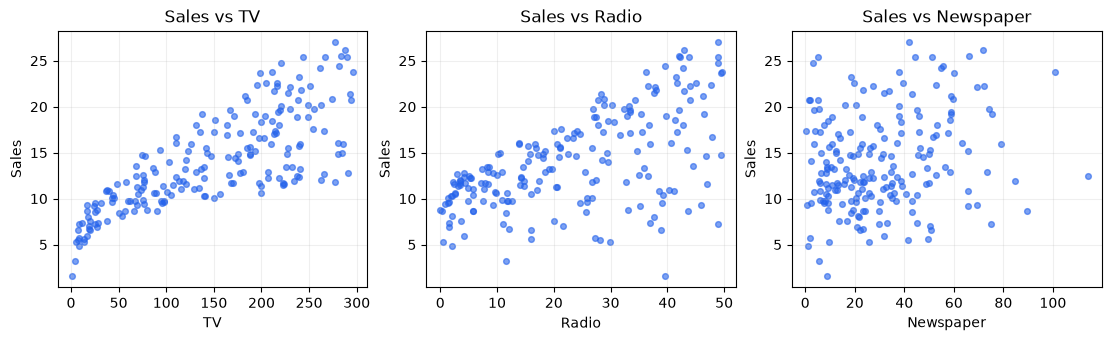

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), layout='constrained')
for feature, ax in zip(FEATURES, axes):
    ax.scatter(data[feature], data[TARGET], s=17, alpha=0.6, color='#2563eb')
    ax.set(xlabel=feature, ylabel='Sales', title=f'Sales vs {feature}')
    ax.grid(alpha=0.2)
plt.show()

The features have different ranges. We use min-max scaling for the iterative
optimizers. A relationship in these plots does not establish that changing an
advertising budget causes a sales change.
All three features are retained; these plots do not select features.

## 3. Define a reproducible comparison

The main experiment uses 160 training rows and 40 held-out test rows. Only
training rows determine the scaling minima and ranges. Test values are
transformed with those same parameters, even when they fall outside [0, 1].

The main comparison uses a learning rate of 0.01, 500 epochs, and a
mini-batch size of 20. The later learning-rate exploration uses training loss
only. We do not choose hyperparameters from test performance.

Every model uses the same split and features. A mean predictor uses only
the mean training sales and provides a reference for test RMSE and R-squared.

In [4]:
config = ExperimentConfig(seed=42, epochs=500, learning_rate=0.01, batch_size=20, timing_repeats=3)
result = run_experiment(DEFAULT_DATA_PATH, config)
print(f"Training rows: {result.metadata['n_train']}; test rows: {result.metadata['n_test']}")
print('Updates per epoch:', result.metadata['updates_per_epoch'])
display(pd.DataFrame({
    'feature': FEATURES,
    'training_minimum': result.metadata['train_feature_minimum'],
    'training_range': result.metadata['train_feature_scale'],
}))

,feature,training_minimum,training_range
0,TV,4.1,292.3
1,Radio,0.0,49.6
2,Newspaper,0.3,113.7


## 4. Compare fitted models

The training objective measures optimization progress. Test RMSE, MAE, and
R-squared measure prediction on the held-out rows. A negative test R-squared
is possible when predictions are worse than the test-set mean reference.

`median_fit_ms` is a separate fit-only benchmark with history recording
disabled. Runtime details are discussed below.

In [5]:
display(result.metrics.style.format(precision=4, na_rep='—'))
display(result.coefficients.style.format(precision=6))

ours = result.models['Least squares'].predict(result.X_test)
reference = result.models['scikit-learn'].predict(result.X_test)
max_difference = np.max(np.abs(ours - reference))
np.testing.assert_allclose(ours, reference, atol=1e-10, rtol=1e-10)
print(f'Maximum prediction difference between least squares and sklearn: {max_difference:.2e}')

,train_half_mse,test_rmse,test_mae,test_r2,median_fit_ms
method,,,,,
Least squares,1.2062,2.0882,1.3111,0.8046,0.0224
Mini-batch GD,1.2428,2.1163,1.3498,0.7993,15.8505
SGD,1.2076,2.1015,1.3089,0.8021,270.5352
scikit-learn,1.2062,2.0882,1.3111,0.8046,0.2050
Mean baseline,13.9248,4.9455,4.1820,-0.0958,—


,intercept,TV,Radio,Newspaper
method,,,,
Least squares,3.095115,0.044997,0.192249,-0.001823
Mini-batch GD,3.471262,0.042968,0.180285,0.005826
SGD,3.118733,0.045060,0.192810,-0.001682
scikit-learn,3.095115,0.044997,0.192249,-0.001823
Mean baseline,14.315000,0.000000,0.000000,0.000000


In [6]:
scores = result.metrics
display(Markdown(
    f"The NumPy least-squares solution and scikit-learn agree numerically. "
    f"Least squares obtains **test RMSE {scores.loc['Least squares', 'test_rmse']:.3f}**, "
    f"compared with **{scores.loc['Mean baseline', 'test_rmse']:.3f}** for the mean baseline. "
    f"At the fixed 500-epoch budget, mini-batch GD has training half MSE "
    f"**{scores.loc['Mini-batch GD', 'train_half_mse']:.4f}** and SGD "
    f"**{scores.loc['SGD', 'train_half_mse']:.4f}**, versus the least-squares minimum "
    f"**{scores.loc['Least squares', 'train_half_mse']:.4f}**. "
    "These differences show finite-budget optimization behavior on this dataset; "
    "they do not establish a generally superior optimizer."
))

The NumPy least-squares solution and scikit-learn agree numerically. Least squares obtains **test RMSE 2.088**, compared with **4.946** for the mean baseline. At the fixed 500-epoch budget, mini-batch GD has training half MSE **1.2428** and SGD **1.2076**, versus the least-squares minimum **1.2062**. These differences show finite-budget optimization behavior on this dataset; they do not establish a generally superior optimizer.

The coefficients above are in the original feature units. Scaling must be
undone for the intercept too. If $z_j=(x_j-m_j)/s_j$, then

$$w_j=\tilde w_j/s_j,\qquad b=\tilde b-\sum_j m_jw_j.$$

`MinMaxScaler.to_original_scale` converts both slopes and intercept.
A test checks that predictions are preserved, including on unseen inputs.

## 5. Inspect convergence

Each curve includes the initial zero-weight loss at epoch 0. Both algorithms
are evaluated on the entire training set after each epoch. The second plot
shows distance from the least-squares training minimum on a log scale.

Epochs align passes over the data, not update counts. With 160 training rows,
SGD makes 160 updates per epoch, while batches of 20 make 8 updates.

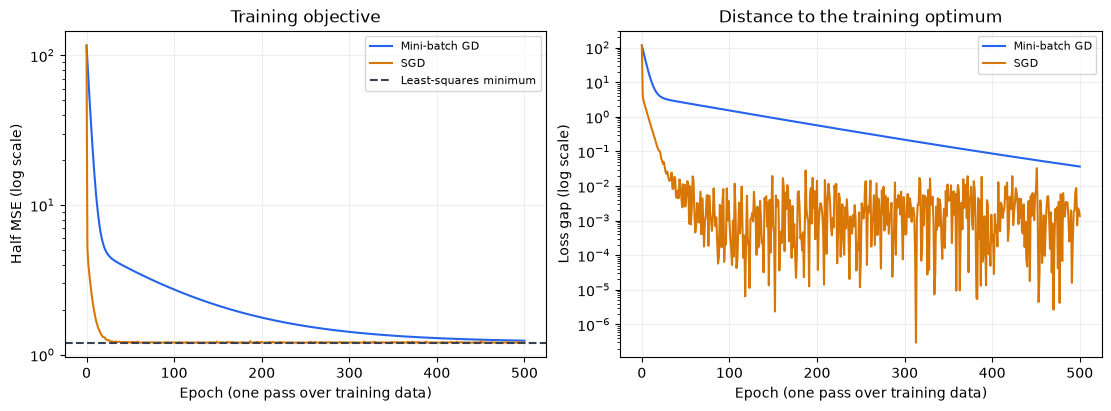

In [7]:
plot_convergence(result)
plt.show()

Mini-batch GD reduces the objective substantially but has not fully reached
the optimum under the fixed learning rate and epoch budget. SGD
makes many more updates in those same epochs. Its constant learning rate
also allows fluctuations near the optimum: individual samples can push
parameters in different directions.

The loss need not fall after every epoch. The least-squares minimum is a
training optimization reference, not a guarantee of the lowest test error.

## 6. Explore learning rate using training data

Keep the split, batch size, epochs, initialization, and shuffle seed fixed.
Compare learning rates 0.001, 0.01, and 0.1. Test metrics are not used in this
comparison, and the main comparison retains the default 0.01 setting.

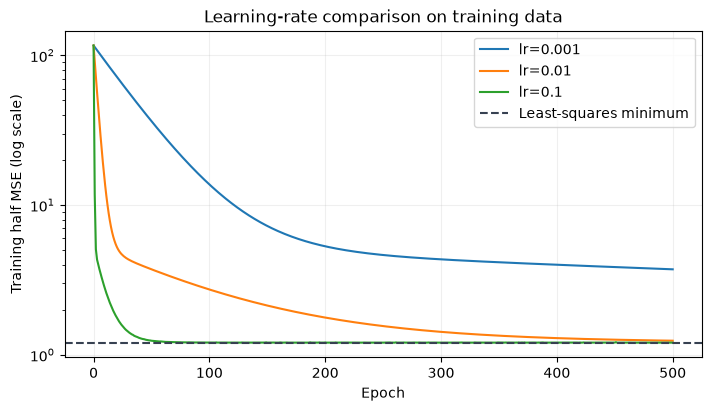

,final_training_half_mse
lr=0.001,3.7253
lr=0.01,1.2428
lr=0.1,1.2062


In [8]:
plot_learning_rates(result)
plt.show()
display(result.learning_rates.drop(columns='epoch').iloc[-1].rename('final_training_half_mse').to_frame())

In [9]:
final_losses = result.learning_rates.drop(columns='epoch').iloc[-1]
display(Markdown(
    f"Within this fixed training-only grid, **{final_losses.idxmin()}** ends with "
    f"the lowest training half MSE (**{final_losses.min():.4f}**). "
    "A small learning rate can require more epochs; increasing it can improve "
    "progress within a fixed budget, but sufficiently large steps can oscillate "
    "or diverge. This grid does not establish a universally best learning rate."
))

Within this fixed training-only grid, **lr=0.1** ends with the lowest training half MSE (**1.2062**). A small learning rate can require more epochs; increasing it can improve progress within a fixed budget, but sufficiently large steps can oscillate or diverge. This grid does not establish a universally best learning rate.

## 7. Compare computational cost

Each fit-only benchmark performs one warmup and then takes the median of three
runs. All data loading, scaling, metric computation, plotting, and loss-history
recording are excluded from the timer. The settings and library versions are
saved in `results/metadata.json`.

The timings compare a direct solver with iterative methods under a **fixed
epoch budget**, not equal final accuracy or equal numbers of updates. This
small three-feature problem favors a direct solve. Python loop overhead makes
one-sample SGD expensive here; batching performs more work per array operation.
The direct solver's advantage on this dataset is not a universal statement
about large or streaming datasets.

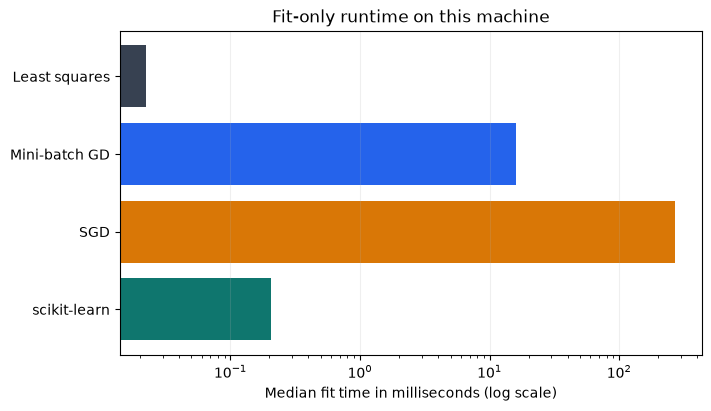

,median_fit_ms
method,
Least squares,0.022
Mini-batch GD,15.850
SGD,270.535
scikit-learn,0.205


In [10]:
plot_runtime(result)
plt.show()
display(result.metrics[['median_fit_ms']].dropna().round(3))

## 8. Inspect held-out predictions

The least-squares model illustrates the common model family. The diagonal
marks perfect predictions; the residual plot exposes large errors that an
aggregate metric alone can hide. Do not tune against these held-out errors;
further model development should use a validation split or cross-validation
inside the training data.

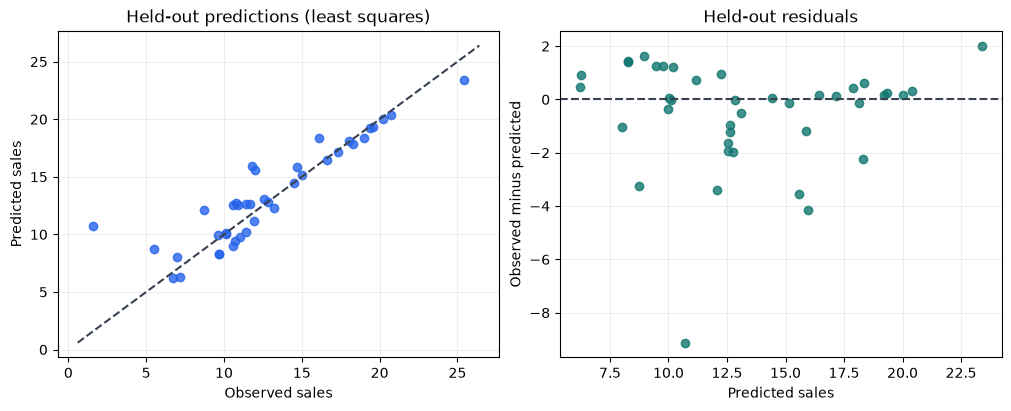

In [11]:
plot_predictions(result)
plt.show()

## 9. Full-data numerical reference

This separate calculation fits **all 200 observations** to report the
least-squares coefficients and training objective on the complete dataset.
Its error is a training error, not a test score. The resulting model is
excluded from the held-out comparison above.

In [12]:
X_all, y_all = data[FEATURES].to_numpy(), data[TARGET].to_numpy()
full_data_model = least_squares(X_all, y_all)
display(pd.Series(
    [full_data_model.intercept, *full_data_model.coef],
    index=['intercept', *FEATURES], name='full_data_coefficients',
).to_frame())
print(f'Full-data training half MSE: {half_mse(y_all, full_data_model.predict(X_all)):.6f}')

,full_data_coefficients
intercept,2.9389
TV,0.0458
Radio,0.1885
Newspaper,-0.0010


## 10. Save the run and interpret its limits

The export below writes the same metrics and coefficients displayed here,
plus convergence histories, plots, split indices, hyperparameters, and the
dataset hash. It does not copy the raw dataset into the results directory.

The main findings are that the NumPy solution matches the library baseline,
both gradient-based methods approach the same training objective, and the
fixed learning rate and update budget affect convergence. Runtime depends on
both algorithmic work and the implementation.

The dataset contains only 200 observations and the test split only 40.
Metrics from this single split have substantial sampling uncertainty. An
additive linear model can miss interactions or nonlinear behavior. A future
extension could evaluate such changes through training-only cross-validation
and a new untouched test set. This project demonstrates regression and
optimization mechanics, not production deployment or causal inference.

In [13]:
save_results(result)
display(pd.Series(result.metadata['packages'], name='version').to_frame())
print('Saved the current run to linear_regression/results/.')

,version
numpy,2.5.4
pandas,2.3.3
scikit-learn,1.9.1
matplotlib,3.11.2


## References

- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*,
  [Advertising dataset](https://www.statlearning.com/resources-second-edition).
- [NumPy `lstsq`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html).
- [scikit-learn `LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).
- [Preprocessing and data leakage](https://scikit-learn.org/stable/common_pitfalls.html).